In [1]:
OPENAI_API_KEY=""
OPENAI_MODEL="gpt-5.6-luna"

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv()

API_KEY = os.getenv("OPENAI_API_KEY",OPENAI_API_KEY)
MODEL_NAME = os.getenv("OPENAI_MODEL", OPENAI_MODEL)

if not API_KEY:
    raise ValueError("OPENAI_API_KEY is missing")

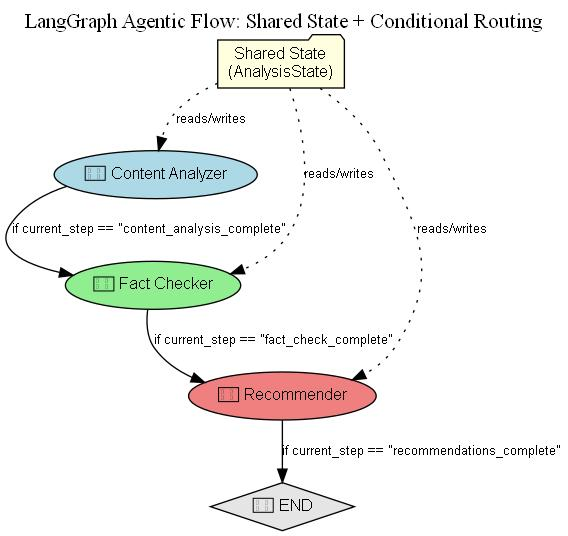

Basic execution flow
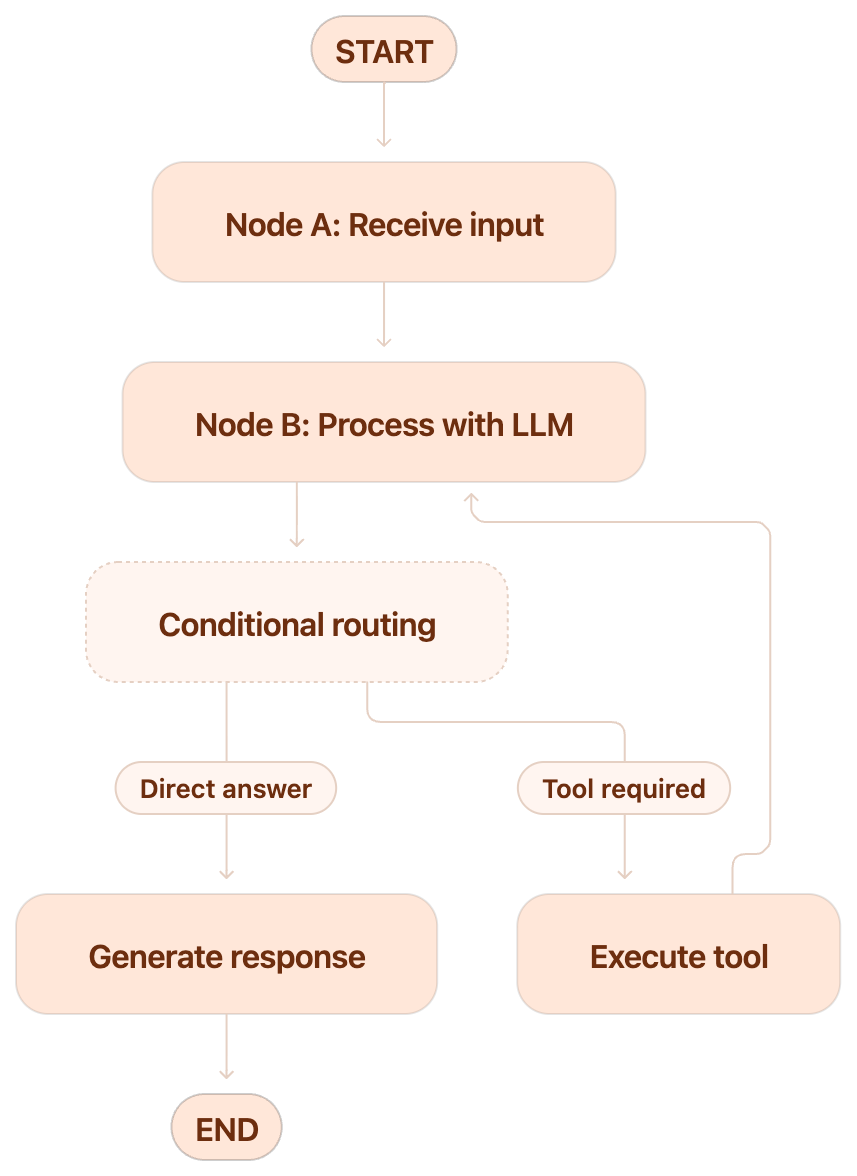

In [ ]:
!pip install langchain_openai langchain_text_splitters langchain_community faiss-cpu -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 68.5 MB/s eta 0:00:00


In [ ]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model=MODEL_NAME,
    use_responses_api=True,
    api_key=OPENAI_API_KEY,
    temperature=0,
)

### First LangGraph workflow

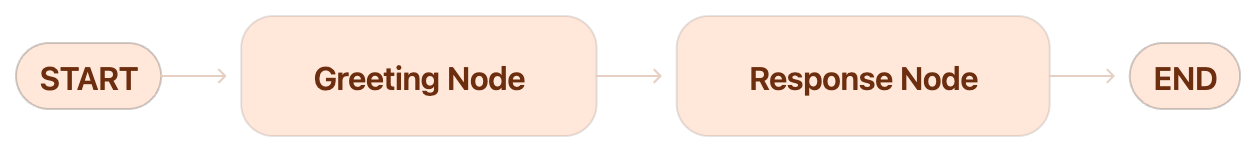

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


# 1. Define shared state
class BasicState(TypedDict):
    name: str
    message: str


# 2. Define nodes
def greeting_node(state: BasicState):
    return {
        "message": f"Hello {state['name']}!"
    }


def response_node(state: BasicState):
    return {
        "message": state["message"] + " Welcome to LangGraph."
    }


# 3. Build graph
builder = StateGraph(BasicState)

builder.add_node("greeting", greeting_node)
builder.add_node("response", response_node)

builder.add_edge(START, "greeting")
builder.add_edge("greeting", "response")
builder.add_edge("response", END)

graph = builder.compile()

# 4. Execute
result = graph.invoke({
    "name": "Sharma",
    "message": ""
})

print(result)

{'name': 'Sharma', 'message': 'Hello Sharma! Welcome to LangGraph.'}


### Build an agent with tools

In [ ]:
from datetime import datetime, timezone

from langchain_core.tools import tool
from langgraph.prebuilt import create_react_agent

@tool
def calculator(expression: str) -> str:
    """Calculate a basic arithmetic expression.

    Args:
        expression: Arithmetic expression, e.g. (25 * 4) + 10.
    """
    import ast
    import operator

    operators = {
        ast.Add: operator.add,
        ast.Sub: operator.sub,
        ast.Mult: operator.mul,
        ast.Div: operator.truediv,
        ast.Pow: operator.pow,
        ast.USub: operator.neg,
    }

    def evaluate(node):
        if isinstance(node, ast.Constant):
            if type(node.value) in (int, float):
                return node.value
            raise ValueError("Only numeric constants are allowed")

        if isinstance(node, ast.BinOp):
            op = operators.get(type(node.op))
            if op is None:
                raise ValueError("Unsupported operator")
            return op(evaluate(node.left), evaluate(node.right))

        if isinstance(node, ast.UnaryOp):
            op = operators.get(type(node.op))
            if op is None:
                raise ValueError("Unsupported unary operator")
            return op(evaluate(node.operand))

        raise ValueError("Unsupported expression")

    if len(expression) > 200:
        raise ValueError("Expression is too long")

    tree = ast.parse(expression, mode="eval")
    return str(evaluate(tree.body))


@tool
def get_current_time() -> str:
    """Get the current UTC date and time."""
    return datetime.now(timezone.utc).isoformat()


@tool
def search_knowledge(query: str) -> str:
    """Search a small internal knowledge base."""

    knowledge = {
        "langgraph": (
            "LangGraph supports stateful workflows, "
            "conditional routing, checkpointing, and interrupts."
        ),
        "rag": (
            "RAG retrieves relevant documents and provides "
            "their content to an LLM for grounded generation."
        ),
        "agent": (
            "An agent uses a model to select tools and "
            "decide what action to take next."
        ),
    }

    query = query.lower()

    matches = [
        value
        for key, value in knowledge.items()
        if key in query
    ]

    return "\n".join(matches) if matches else "No matching documents."


In [ ]:
tools = [
    calculator,
    get_current_time,
    search_knowledge,
]

agent = create_react_agent(
    model=llm,
    tools=tools,
    prompt=(
        "You are a technical assistant. "
        "Use tools when needed. "
        "Do not invent calculation results. "
        "Explain your answer clearly."
    ),
)

result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": (
                "What is 125 * 48? Also explain "
                "what LangGraph is."
            ),
        }
    ]
})

print(result["messages"][-1].content)

/tmp/ipykernel_2853/2852385062.py:7: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agent = create_react_agent(


[{'type': 'text', 'text': '**125 × 48 = 6,000**\n\n**LangGraph** is a framework for building stateful, multi-step workflows with language models and agents. It represents a workflow as a graph:\n\n- **Nodes** perform tasks, such as calling an LLM or a tool.\n- **Edges** control the flow between tasks.\n- **State** stores information as the workflow progresses.\n- It supports conditional routing, checkpointing, and human-in-the-loop interruptions.\n\nIt is useful for creating reliable agents that need to reason through multiple steps, maintain context, and recover or pause during execution.', 'annotations': [], 'id': 'msg_0ebdc89a6c607af9006ab7a6dbe8a887d2ad51806601858510', 'phase': 'final_answer'}]


Reasoning and Acting Loop
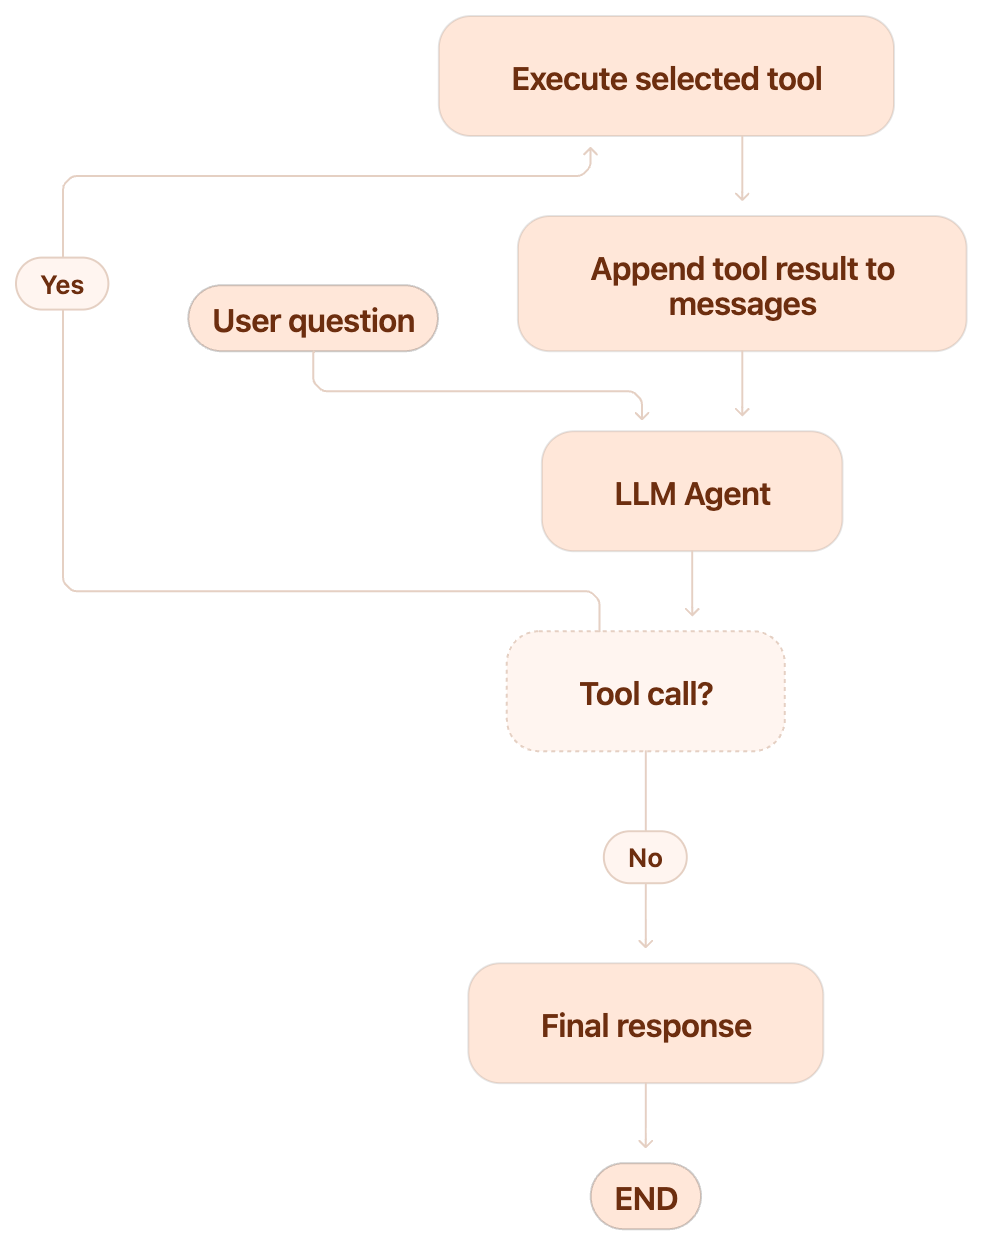

### State management

In [ ]:
from typing import TypedDict, Annotated
from operator import add

from langgraph.graph import StateGraph, START, END


class ResearchState(TypedDict):
    question: str
    plan: list[str]

    # Append new findings instead of replacing old ones
    findings: Annotated[list[str], add]

    answer: str
    retry_count: int


def planner(state: ResearchState):
    question = state["question"]

    return {
        "plan": [
            f"Understand the question: {question}",
            "Collect supporting information",
            "Generate a final answer",
        ]
    }


def collect_findings(state: ResearchState):
    return {
        "findings": [
            "LangGraph is a stateful orchestration framework."
        ]
    }


def answer_question(state: ResearchState):
    findings = "\n".join(state["findings"])

    return {
        "answer": (
            f"Question: {state['question']}\n"
            f"Findings: {findings}"
        )
    }


builder = StateGraph(ResearchState)

builder.add_node("planner", planner)
builder.add_node("collect", collect_findings)
builder.add_node("answer", answer_question)

builder.add_edge(START, "planner")
builder.add_edge("planner", "collect")
builder.add_edge("collect", "answer")
builder.add_edge("answer", END)

graph = builder.compile()

result = graph.invoke({
    "question": "What is LangGraph?",
    "plan": [],
    "findings": [],
    "answer": "",
    "retry_count": 0,
})

print(result)

{'question': 'What is LangGraph?', 'plan': ['Understand the question: What is LangGraph?', 'Collect supporting information', 'Generate a final answer'], 'findings': ['LangGraph is a stateful orchestration framework.'], 'answer': 'Question: What is LangGraph?\nFindings: LangGraph is a stateful orchestration framework.', 'retry_count': 0}


#### With Memory

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from typing import TypedDict


class CounterState(TypedDict):
    count: int


def increment(state: CounterState):
    return {"count": state["count"] + 1}


builder = StateGraph(CounterState)
builder.add_node("increment", increment)

builder.add_edge(START, "increment")
builder.add_edge("increment", END)

memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)

config = {
    "configurable": {
        "thread_id": "session-001"
    }
}

first = graph.invoke({"count": 0}, config=config)
print(first["count"])  # 1

second = graph.invoke(None, config=config)
print(second["count"])  # 2

1
1


### Conditional workflows

Workflow design

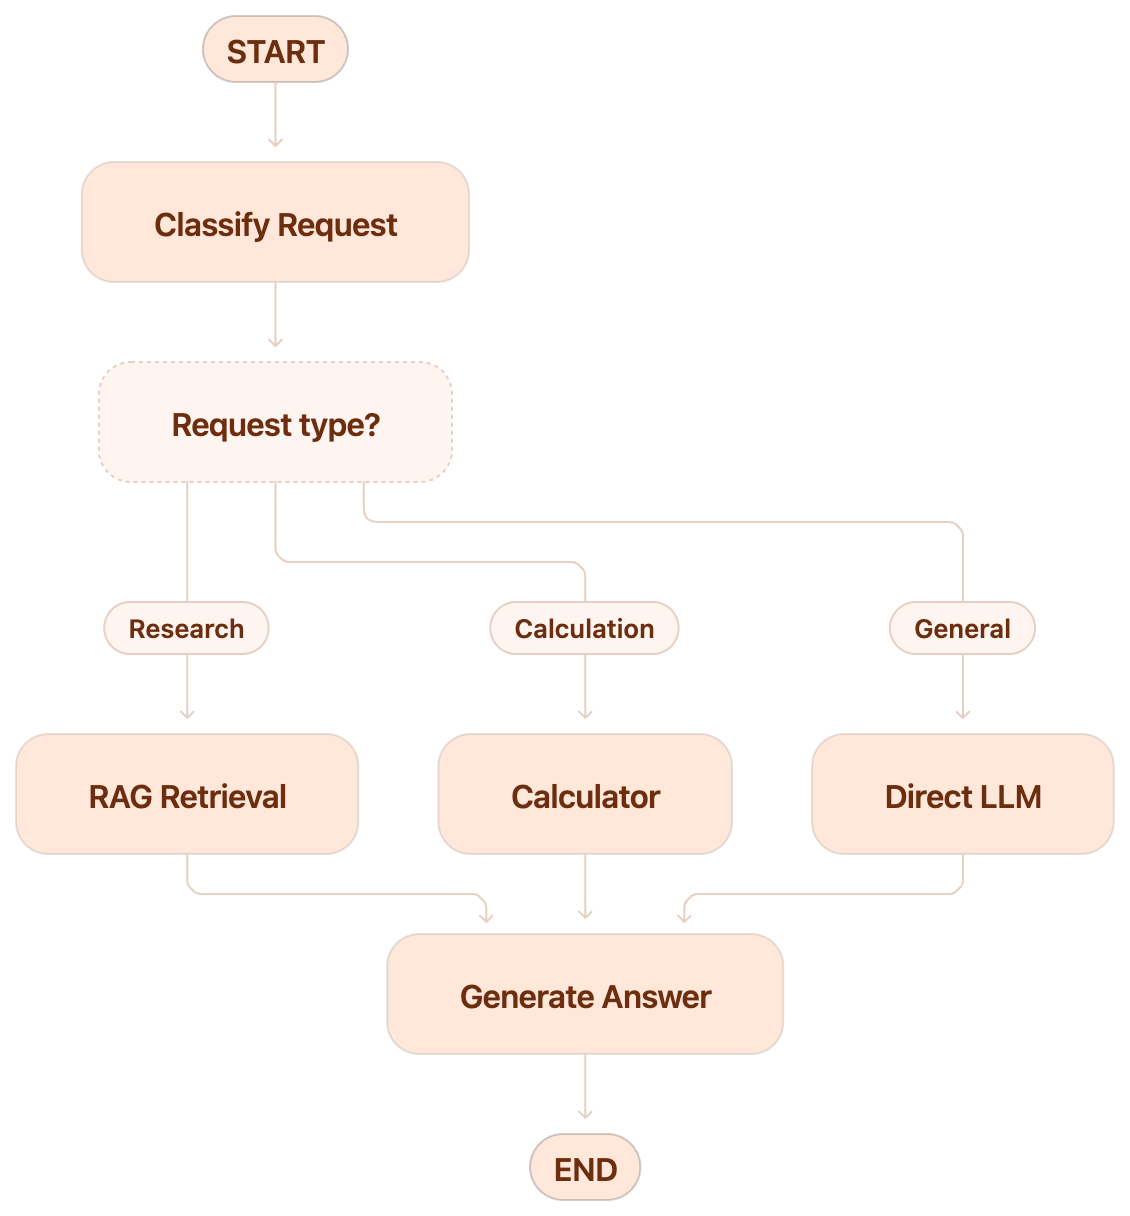

In [ ]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage

class WorkflowState(TypedDict):
    question: str
    category: str
    context: str
    answer: str


def classify(state: WorkflowState):
    question = state["question"]

    prompt = f"""
    Classify this request into exactly one category:
    research, calculation, general.

    Request: {question}

    Return only the category.
    """

    result = llm.invoke(prompt)
    category = result.content[0]['text']

    if category not in {"research", "calculation", "general"}:
        category = "general"

    return {"category": category}


def route_request(
    state: WorkflowState
) -> Literal["research", "calculation", "general"]:

    return state["category"]


def research_node(state: WorkflowState):
    # Replace with real retriever in Module 5
    return {
        "context": (
            "LangGraph supports state, nodes, "
            "conditional edges, and checkpointing."
        )
    }


def calculation_node(state: WorkflowState):
    # Demonstration only: replace with safe calculator tool
    return {
        "context": "Use the calculator tool for arithmetic."
    }


def general_node(state: WorkflowState):
    return {"context": "No additional context required."}


def generate_answer(state: WorkflowState):
    response = llm.invoke([
        HumanMessage(
            content=(
                f"Question: {state['question']}\n"
                f"Context: {state['context']}\n"
                "Answer the user accurately."
            )
        )
    ])

    return {"answer": response.content}


In [ ]:
builder = StateGraph(WorkflowState)

builder.add_node("classify", classify)
builder.add_node("research", research_node)
builder.add_node("calculation", calculation_node)
builder.add_node("general", general_node)
builder.add_node("answer", generate_answer)

builder.add_edge(START, "classify")

builder.add_conditional_edges(
    "classify",
    route_request,
    {
        "research": "research",
        "calculation": "calculation",
        "general": "general",
    },
)

builder.add_edge("research", "answer")
builder.add_edge("calculation", "answer")
builder.add_edge("general", "answer")
builder.add_edge("answer", END)

graph = builder.compile()

result = graph.invoke({
    "question": "Explain how LangGraph manages state.",
    "category": "",
    "context": "",
    "answer": "",
})

print(result["category"])
print(result["answer"])

general
[{'id': 'rs_01ee3c2690d16f5d006ab7a818e8e887d2832bffa4506feb21', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABqt6gkuQzFXqgg3YF_xQ3EMKUKkSpP4I3xTb-PauBoQDRdiR62RpUputSvrlAIRckIdxllqnFCx8n-3AuwL_x7cenaORM_SGl_RDuiGfzWE-L3HUMstOX14tLKsgy-krqRalYy8TlKP_htYzs5LRZ6SPWyMDpMXx6EI-kVfe1GPvKdq_K5pwJgixaWZf1bZy0AOHUIO_p14DrkCy9JJ1PhHxhqDV4vDJT7RSgLFxBDHwbZbe6aHZOJSD0-QmF9_P6Kb1s4XBc5Qm-FquZmOYNxK-SWi4mRuJVD1o5mVvCh9m5p2hq96RCvTy82doFJPXzz5MHCw-icm1IMtPINkakWDpQhg_tcanX54Q-HQiHtaSAtB6JfqM3WvtLUh4ky4jY_WaSTG8GPKxvesjB-tldxz4aKpW5eJZK8phhy9gzDuxU_ioN3bd1ZApfOCGOGfT7zznKPqu-mcjEgWeE_gZZKrDIZFuMdL3RkTWl-kzID9xFl2eBajtYBwQR-pDFa-MEppTOhdpxws-kyY_uwnhRQ1h9U9Hw4mgX6hCOqNTG2uvNSVbeiD6tkyXuDmzN2yG8DF3hqhkhygm9IECGUdQhhbU2sPUpqmDvQk4eHA4UWicLyRVj18bg8ltYAJZu0_KvSKexZ0jmBK3kPxHAIbQkybKrR8j6OVlBrCGs4z0MFmULx8Wpd4Oz7Zbmg7HGiUXEhhJG3efuosXNdKC-obw74_zONOsMShHBxMIN_NbxtQI6GsCTKk_u-w9CThX3Jnj9o3QWznngP-k7q4jJBdrUyLuwwJLakYdLhpb-G4mDGPWaOcgdVAeKF2n7VcV-n7KJoRMHq_JJ3xIzD8A

In [ ]:
print(result["answer"][1]['text'])

LangGraph manages state as a collection of named values that flow through a graph of nodes.

### 1. Define a state schema

You define the fields that may exist in the graph state, commonly with `TypedDict`, dataclasses, or Pydantic models:

```python
from typing import Annotated
from typing_extensions import TypedDict
import operator

class State(TypedDict):
    question: str
    answer: str
    messages: Annotated[list, operator.add]
```

Each field is effectively a state channel.

### 2. Nodes read state and return updates

A node receives the current state and returns only the fields it wants to update:

```python
def answer_question(state: State):
    result = call_model(state["question"])
    return {
        "answer": result,
        "messages": [{"role": "assistant", "content": result}],
    }
```

Nodes generally should not mutate the state object directly. LangGraph applies the returned updates to produce the next state.

### 3. Reducers determine how updates are combined

Eac

### RAG integration with LangGraph

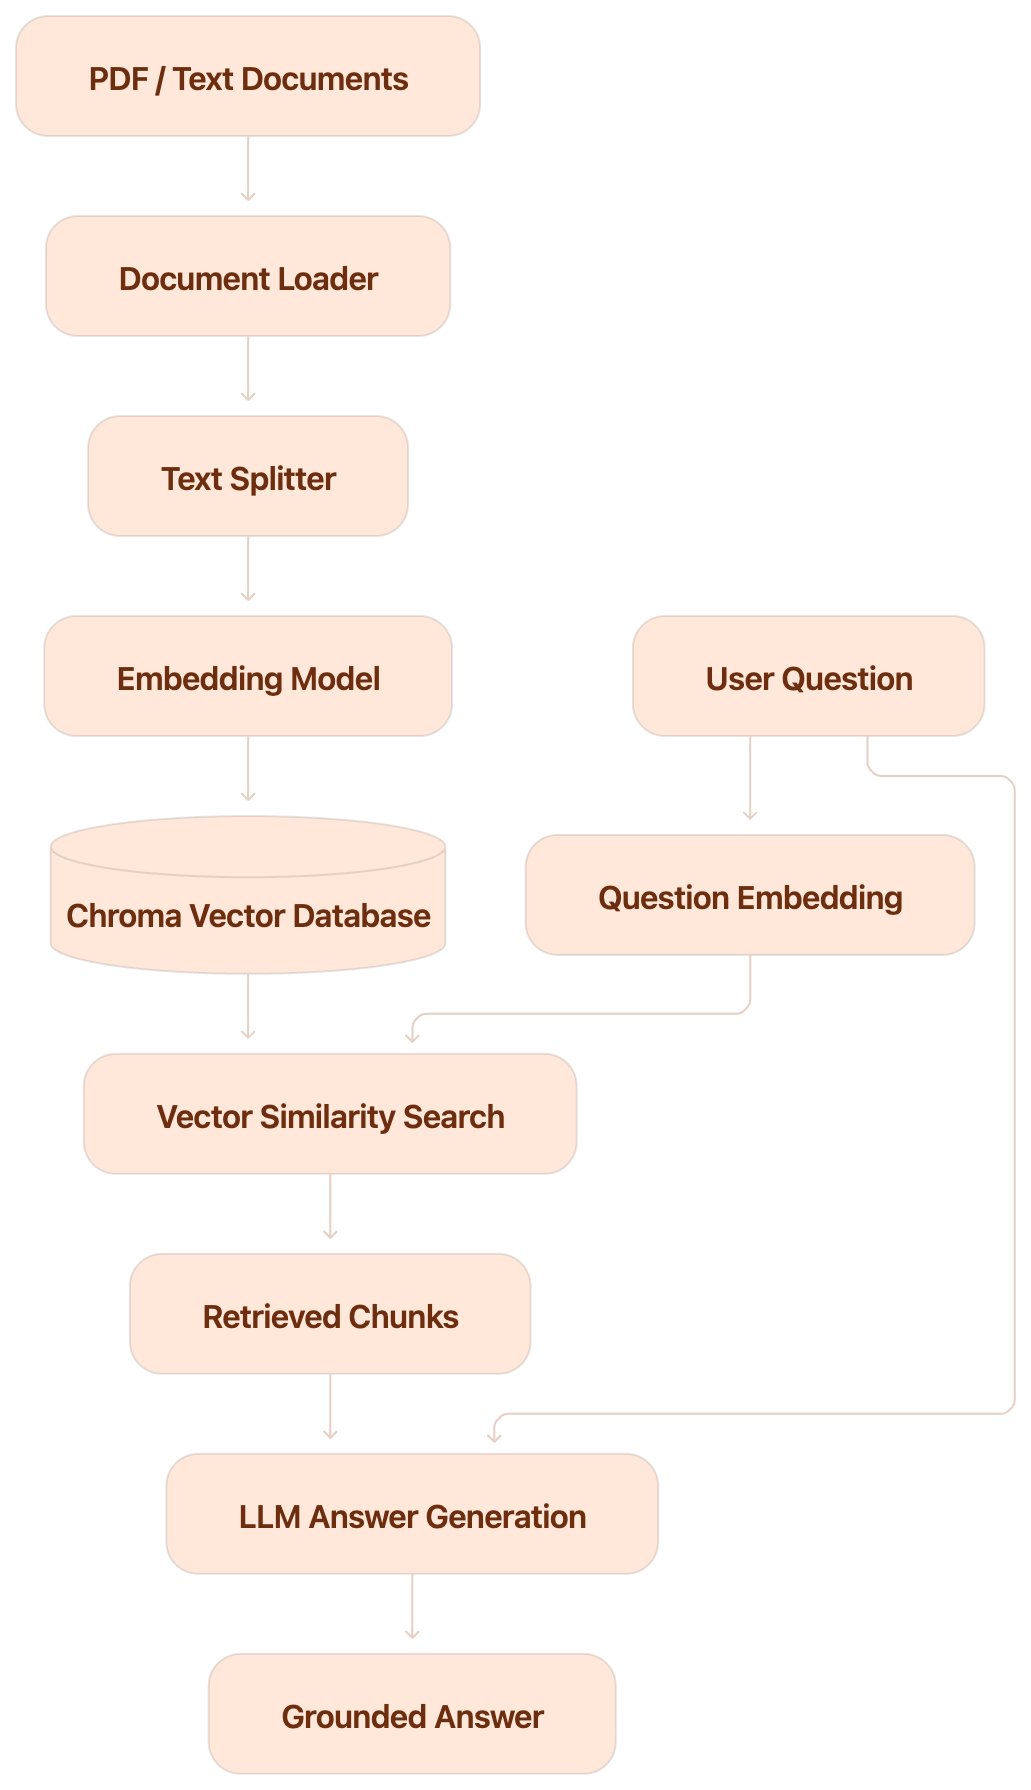

In [ ]:
# offline process
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import FAISS


documents = [
    Document(
        page_content=(
            "LangGraph is a framework for building "
            "stateful, multi-step applications with LLMs. "
            "It supports nodes, edges, conditional routing, "
            "persistence, and human-in-the-loop workflows."
        ),
        metadata={"source": "langgraph_notes.txt"},
    ),
    Document(
        page_content=(
            "Retrieval augmented generation retrieves relevant "
            "documents from a knowledge base and passes them "
            "to a language model as context. The model uses "
            "that context to produce a grounded answer."
        ),
        metadata={"source": "rag_notes.txt"},
    ),
    Document(
        page_content=(
            "Human-in-the-loop workflows can pause execution "
            "using an interrupt. A human can review the pending "
            "action and resume execution with a decision."
        ),
        metadata={"source": "hitl_notes.txt"},
    ),
]


/tmp/ipykernel_628/2663427613.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [ ]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=50,
)

chunks = splitter.split_documents(documents)


In [ ]:
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    api_key=OPENAI_API_KEY,
)

vectorstore = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings
)


In [ ]:
retriever = vectorstore.as_retriever(
    search_kwargs={"k": 3}
)

results = retriever.invoke(
    "How does LangGraph support human approval?"
)

for doc in results:
    print(doc.page_content)
    print(doc.metadata)

LangGraph is a framework for building stateful, multi-step applications with LLMs. It supports nodes, edges, conditional routing, persistence, and human-in-the-loop workflows.
{'source': 'langgraph_notes.txt'}
Human-in-the-loop workflows can pause execution using an interrupt. A human can review the pending action and resume execution with a decision.
{'source': 'hitl_notes.txt'}
Retrieval augmented generation retrieves relevant documents from a knowledge base and passes them to a language model as context. The model uses that context to produce a grounded answer.
{'source': 'rag_notes.txt'}


In [ ]:
# RAG Online Process
# 05_rag_graph.py

from typing import TypedDict

from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage


class RAGState(TypedDict):
    question: str
    context: str
    sources: list[str]
    answer: str


retriever = vectorstore.as_retriever(
    search_kwargs={"k": 3}
)


def retrieve(state: RAGState):
    docs = retriever.invoke(state["question"])

    context = "\n\n".join(
        doc.page_content for doc in docs
    )

    sources = list({
        doc.metadata.get("source", "unknown")
        for doc in docs
    })

    return {
        "context": context,
        "sources": sources,
    }


def generate(state: RAGState):
    prompt = f"""
    You are a technical research assistant.

    Answer the question using only the provided context.
    If the context does not contain the answer, say so.

    Context:
    {state['context']}

    Question:
    {state['question']}
    """

    response = llm.invoke([
        HumanMessage(content=prompt)
    ])

    return {"answer": response.content}


builder = StateGraph(RAGState)

builder.add_node("retrieve", retrieve)
builder.add_node("generate", generate)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "generate")
builder.add_edge("generate", END)

graph = builder.compile()

result = graph.invoke({
    "question": "How does human approval work in LangGraph?",
    "context": "",
    "sources": [],
    "answer": "",
})

print("ANSWER:", result["answer"])
print("SOURCES:", result["sources"])

ANSWER: [{'id': 'rs_05b06aec84406906006ab8893305e487d0aff1b82bb1b8d69c', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABquIk0622gzdTwKIt0Bt_9yx6eLb54tPoykXBdw-5Meu7cp-HkGBMSBDVCIB3BXNqsU1FLKOBmeL_txJd8n5kVTUKlZLIh9fccACAnppXiLox1vRP0T1AycvOtitKch4jOtKARS9OmjZVIs-ScmN2gLoOBICdV7D0K41NVLnS8QDQzOYS9o3h9PkMhsTtUYNE5WobbR6yjjajgsK08hixi6zZQuoyHIih9BgQysQqODxyWugmLKcKPO7OBfwaWLs0Nm21yKKo1bGBtqYM_gdAs7dRROp8chCfZVtTeM00_u16RGv2FGXg347Fy0Gn_Ur00HGXs3X7pTzLCPPXH_b2W6xsJhOOli9TIKYJDvj96ufY4IrM6ICGOpUZAajSY-QWHFafj3OGNGoPUbPKntrGMKYsxQA2wzjfASwHIqwv1RFWqwHwf-PnzJdqeAkf5vbY3Pa6AHnKU1k_XmbFN063UK4XGJV7oxtQFh-87rSKkQ9vMYUnYr83iWczlSAiPD0v_zCUPlys8IMEZyNFjL-8sCF__pXByq-vmkew_Xdz0XicvUrSmCoIjgoI3JZNgITRjJ36tsxjs1miFCFk00qae2an3SbR0FVjEuy25mcN42eayP5OrEZf9c6MSeP149kUFWWZSdCY-augrV7gWUtRmadgAb_RVWuLVKmNU5DQi7oVFq93rR7_OkJrMlRbgOjmcZ-_eb_DZG-9k31qGKYIVuwID8_tEOkyf1TytHdFQuckI_MOA-L8XExfWSX2u8Vn6oxhO9SW7p-QTKmcxZzNCFshLZ2D9xodGwRBXPXEAuwCB3Dp9jXiIedkK_CEStYeBUg7_8cDSvPw_iH

### Human-in-the-loop (HITL)

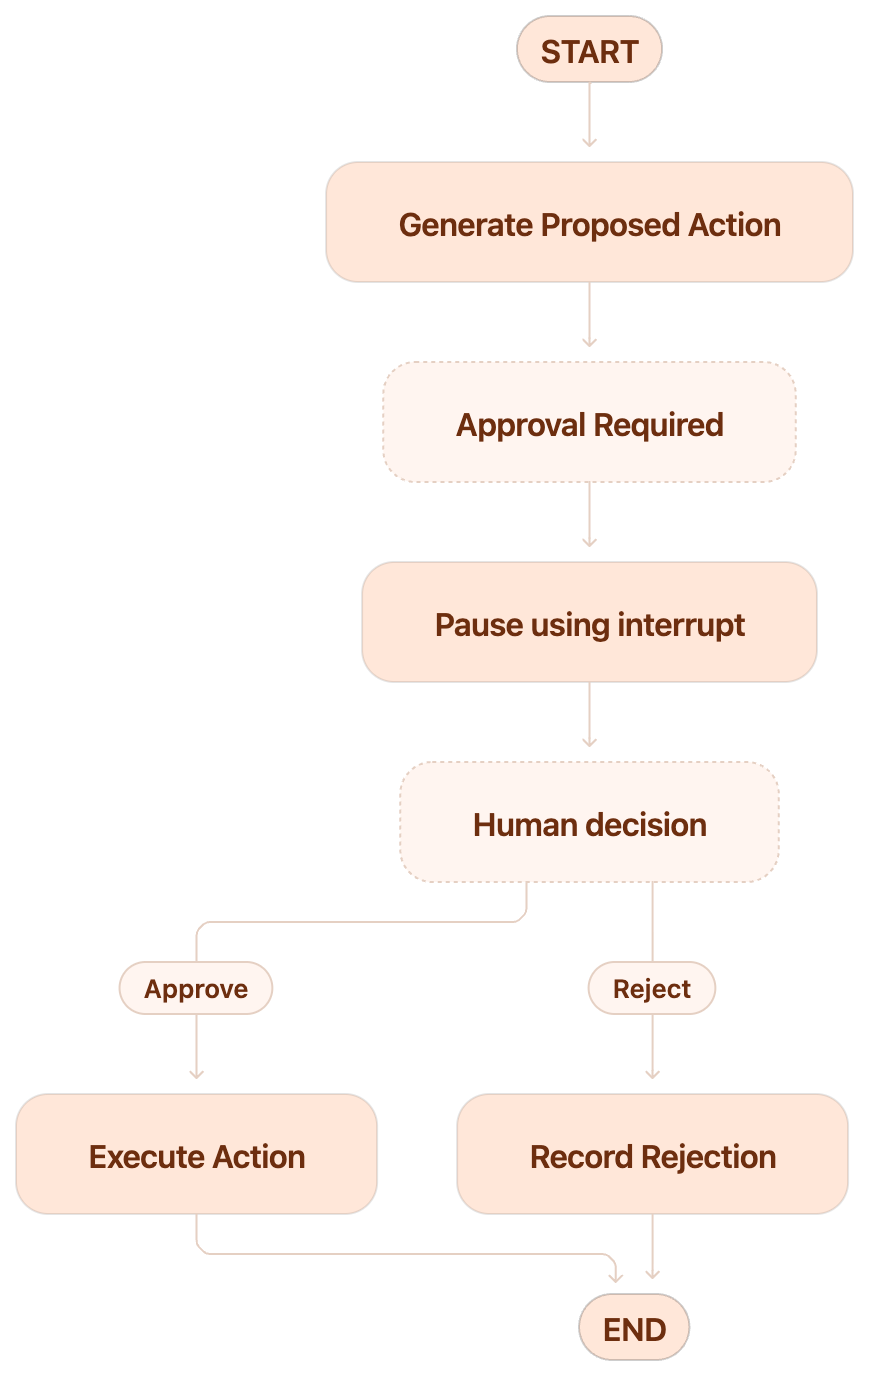

In [ ]:
from typing import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver


class ApprovalState(TypedDict):
    action: str
    approved: bool
    result: str


def propose_action(state: ApprovalState):
    return {
        "action": state["action"]
    }


def human_approval(state: ApprovalState):
    decision = interrupt({
        "message": "Please review this action.",
        "proposed_action": state["action"],
    })

    return {
        "approved": decision["approved"]
    }


def execute_action(state: ApprovalState):
    if not state["approved"]:
        return {
            "result": "Action rejected by human."
        }

    # Demonstration only. Replace with an actual
    # application operation after authorization.
    return {
        "result": f"Approved action: {state['action']}"
    }


def route_after_approval(state: ApprovalState):
    if state["approved"]:
        return "execute"

    return "end"


builder = StateGraph(ApprovalState)

builder.add_node("propose", propose_action)
builder.add_node("approve", human_approval)
builder.add_node("execute", execute_action)

builder.add_edge(START, "propose")
builder.add_edge("propose", "approve")

builder.add_conditional_edges(
    "approve",
    route_after_approval,
    {
        "execute": "execute",
        "end": END,
    },
)

builder.add_edge("execute", END)

checkpointer = InMemorySaver()

graph = builder.compile(
    checkpointer=checkpointer
)


# Initial execution
config = {
    "configurable": {
        "thread_id": "approval-001"
    }
}

result = graph.invoke(
    {
        "action": "Send a customer notification",
        "approved": False,
        "result": "",
    },
    config=config,
)

print("Paused state:", result)

# Inspect the pending interrupt
snapshot = graph.get_state(config)

print("Next node:", snapshot.next)
print("Interrupts:", snapshot.tasks[0].interrupts)


# Resume with a human decision
resume_result = graph.invoke(
    Command(resume={"approved": True}),
    config=config,
)

print("Final result:", resume_result)

Paused state: {'action': 'Send a customer notification', 'approved': False, 'result': '', '__interrupt__': [Interrupt(value={'message': 'Please review this action.', 'proposed_action': 'Send a customer notification'}, id='6ad9e7eb5ba0147f6d04a0e80a5485bf')]}
Next node: ('approve',)
Interrupts: (Interrupt(value={'message': 'Please review this action.', 'proposed_action': 'Send a customer notification'}, id='6ad9e7eb5ba0147f6d04a0e80a5485bf'),)
Final result: {'action': 'Send a customer notification', 'approved': True, 'result': 'Approved action: Send a customer notification'}


#### Adding rejection and editing

In [ ]:
from typing import TypedDict, Literal

from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver


# --------------------------------------------------
# 1. Define state
# --------------------------------------------------

class ApprovalState(TypedDict):
    action: str
    approved: bool
    result: str


# --------------------------------------------------
# 2. Propose an action
# --------------------------------------------------

def propose_action(state: ApprovalState):
    print("\nProposed action:", state["action"])

    return {}


# --------------------------------------------------
# 3. Human approval: Approve / Reject / Edit
# --------------------------------------------------

def human_approval(state: ApprovalState):

    # Pause graph and wait for human input
    decision = interrupt({
        "message": "Review the proposed action",
        "proposed_action": state["action"],
        "options": ["approve", "reject", "edit"],
    })

    # Validate the decision
    if not isinstance(decision, dict):
        raise ValueError("Decision must be a dictionary")

    choice = decision.get("decision")

    if choice == "approve":
        return {
            "approved": True
        }

    elif choice == "reject":
        return {
            "approved": False
        }

    elif choice == "edit":

        updated_action = decision.get("updated_action")

        if not isinstance(updated_action, str):
            raise ValueError("Updated action must be a string")

        if not updated_action.strip():
            raise ValueError("Updated action cannot be empty")

        # Update action, but do NOT approve it yet
        return {
            "action": updated_action.strip(),
            "approved": False,
        }

    else:
        raise ValueError(
            "Invalid decision. Choose approve, reject, or edit."
        )


# --------------------------------------------------
# 4. Route after human decision
# --------------------------------------------------

def route_after_approval(
    state: ApprovalState,
) -> Literal["execute", "review", "end"]:

    # If approved, execute
    if state["approved"]:
        return "execute"

    # If edited, require another human review
    # The updated action is not automatically approved
    if state["result"] == "EDIT_REQUIRED":
        return "review"

    return "end"


# --------------------------------------------------
# 5. Execute the action
# --------------------------------------------------

def execute_action(state: ApprovalState):

    print("\nExecuting approved action:")
    print(state["action"])

    # Replace this with your real business operation
    # e.g., send email, call API, update database

    return {
        "result": f"Successfully executed: {state['action']}"
    }


# --------------------------------------------------
# 6. Handle rejection
# --------------------------------------------------

def reject_action(state: ApprovalState):

    print("\nAction rejected.")

    return {
        "result": "Action rejected by human."
    }


# --------------------------------------------------
# 7. Handle edited action
# --------------------------------------------------

def mark_for_review(state: ApprovalState):

    print("\nEdited action requires approval:")
    print(state["action"])

    return {
        "result": ""
    }


# --------------------------------------------------
# 8. Build graph
# --------------------------------------------------

builder = StateGraph(ApprovalState)

builder.add_node("propose", propose_action)
builder.add_node("approve", human_approval)
builder.add_node("execute", execute_action)
builder.add_node("reject", reject_action)
builder.add_node("review", mark_for_review)

builder.add_edge(START, "propose")
builder.add_edge("propose", "approve")

builder.add_conditional_edges(
    "approve",
    route_after_approval,
    {
        "execute": "execute",
        "review": "review",
        "end": "reject",
    },
)

# After editing, ask for approval again
builder.add_edge("review", "approve")

builder.add_edge("execute", END)
builder.add_edge("reject", END)


# --------------------------------------------------
# 9. Compile with checkpointer
# --------------------------------------------------

checkpointer = InMemorySaver()

graph = builder.compile(
    checkpointer=checkpointer
)


# --------------------------------------------------
# 10. Execute workflow
# --------------------------------------------------

config = {
    "configurable": {
        "thread_id": "approval-session-001"
    }
}

result = graph.invoke(
    {
        "action": "Send an email to the customer",
        "approved": False,
        "result": "",
    },
    config=config,
)

print("\nWorkflow paused for approval.")
print(graph.get_state(config).tasks[0].interrupts[0].value)


# --------------------------------------------------
# 11. Resume with human decisions
# --------------------------------------------------

while True:

    decision = input(
        "\nEnter approve / reject / edit: "
    ).strip().lower()

    if decision == "approve":

        result = graph.invoke(
            Command(
                resume={
                    "decision": "approve"
                }
            ),
            config=config,
        )

        break

    elif decision == "reject":

        result = graph.invoke(
            Command(
                resume={
                    "decision": "reject"
                }
            ),
            config=config,
        )

        break

    elif decision == "edit":

        updated_action = input(
            "Enter the updated action: "
        ).strip()

        result = graph.invoke(
            Command(
                resume={
                    "decision": "edit",
                    "updated_action": updated_action,
                }
            ),
            config=config,
        )

        print("\nUpdated action submitted.")
        print(
            graph.get_state(config)
            .tasks[0].interrupts[0].value
        )

        # Continue loop to obtain approval for edited action
        continue

    else:
        print("Invalid choice. Try again.")


print("\nFinal workflow state:")
print(result)


Proposed action: Send an email to the customer

Workflow paused for approval.
{'message': 'Review the proposed action', 'proposed_action': 'Send an email to the customer', 'options': ['approve', 'reject', 'edit']}

Enter approve / reject / edit: reject

Action rejected.

Final workflow state:
{'action': 'Send an email to the customer', 'approved': False, 'result': 'Action rejected by human.'}


### Workflow control

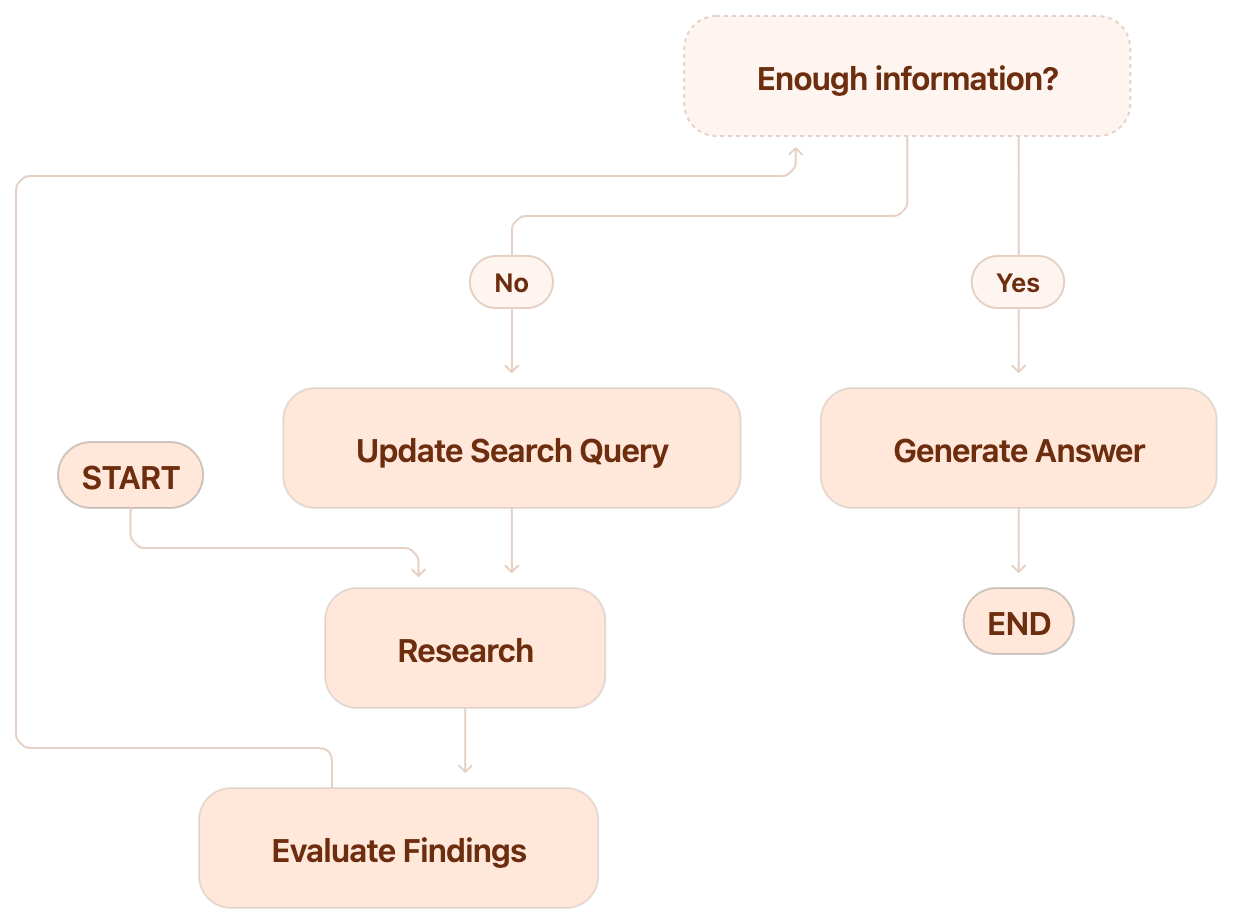

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class LoopState(TypedDict):
    query: str
    iterations: int
    sufficient: bool
    findings: list[str]
    answer: str


MAX_ITERATIONS = 3


def research(state: LoopState):
    return {
        "findings": [
            f"Research result for: {state['query']}"
        ],
        "iterations": state["iterations"] + 1,
    }


def evaluate(state: LoopState):
    sufficient = (
        len(state["findings"]) >= 2
        or state["iterations"] >= MAX_ITERATIONS
    )

    return {"sufficient": sufficient}


def route_research(state: LoopState):
    if state["sufficient"]:
        return "answer"

    return "research"


def answer(state: LoopState):
    return {
        "answer": "\n".join(state["findings"])
    }


builder = StateGraph(LoopState)

builder.add_node("research", research)
builder.add_node("evaluate", evaluate)
builder.add_node("answer", answer)

builder.add_edge(START, "research")
builder.add_edge("research", "evaluate")

builder.add_conditional_edges(
    "evaluate",
    route_research,
    {
        "research": "research",
        "answer": "answer",
    },
)

builder.add_edge("answer", END)

graph = builder.compile()

result = graph.invoke({
    "query": "LangGraph workflows",
    "iterations": 0,
    "sufficient": False,
    "findings": [],
    "answer": "",
})

print(result)

{'query': 'LangGraph workflows', 'iterations': 3, 'sufficient': True, 'findings': ['Research result for: LangGraph workflows'], 'answer': 'Research result for: LangGraph workflows'}


In [ ]:
result = graph.invoke({
    "query": "Explain LangGraph architecture",
    "iterations": 0,
    "sufficient": False,
    "findings": [],
    "answer": "",
})
print(result)

{'query': 'Explain LangGraph architecture', 'iterations': 3, 'sufficient': True, 'findings': ['Research result for: Explain LangGraph architecture'], 'answer': 'Research result for: Explain LangGraph architecture'}


In [ ]:
result = graph.invoke({
    "query": (
        "Compare LangGraph, LangChain agents, "
        "and traditional workflows with examples"
    ),
    "iterations": 0,
    "sufficient": False,
    "findings": [],
    "answer": "",
})
print(result)

{'query': 'Compare LangGraph, LangChain agents, and traditional workflows with examples', 'iterations': 3, 'sufficient': True, 'findings': ['Research result for: Compare LangGraph, LangChain agents, and traditional workflows with examples'], 'answer': 'Research result for: Compare LangGraph, LangChain agents, and traditional workflows with examples'}


In [ ]:
result = graph.invoke({
    "query": (
        "Design a production RAG agent with PostgreSQL "
        "checkpointing, human approval, retries, "
        "and conditional routing"
    ),
    "iterations": 0,
    "sufficient": False,
    "findings": [],
    "answer": "",
})
result

{'query': 'Design a production RAG agent with PostgreSQL checkpointing, human approval, retries, and conditional routing',
 'iterations': 3,
 'sufficient': True,
 'findings': ['Research result for: Design a production RAG agent with PostgreSQL checkpointing, human approval, retries, and conditional routing'],
 'answer': 'Research result for: Design a production RAG agent with PostgreSQL checkpointing, human approval, retries, and conditional routing'}

### Capstone project: AI Research Assistant

**Requirements**

* Build an AI Research Assistant that:
* Classifies user questions into research, calculation, or general.
* Uses RAG for research questions.
* Calls a calculator tool for calculations.
* Generates an answer using an LLM.
* Evaluates whether the answer is sufficient.
* Retries research when evidence is insufficient.
* Requires human approval before sending a report.
* Stores state using a checkpointer.

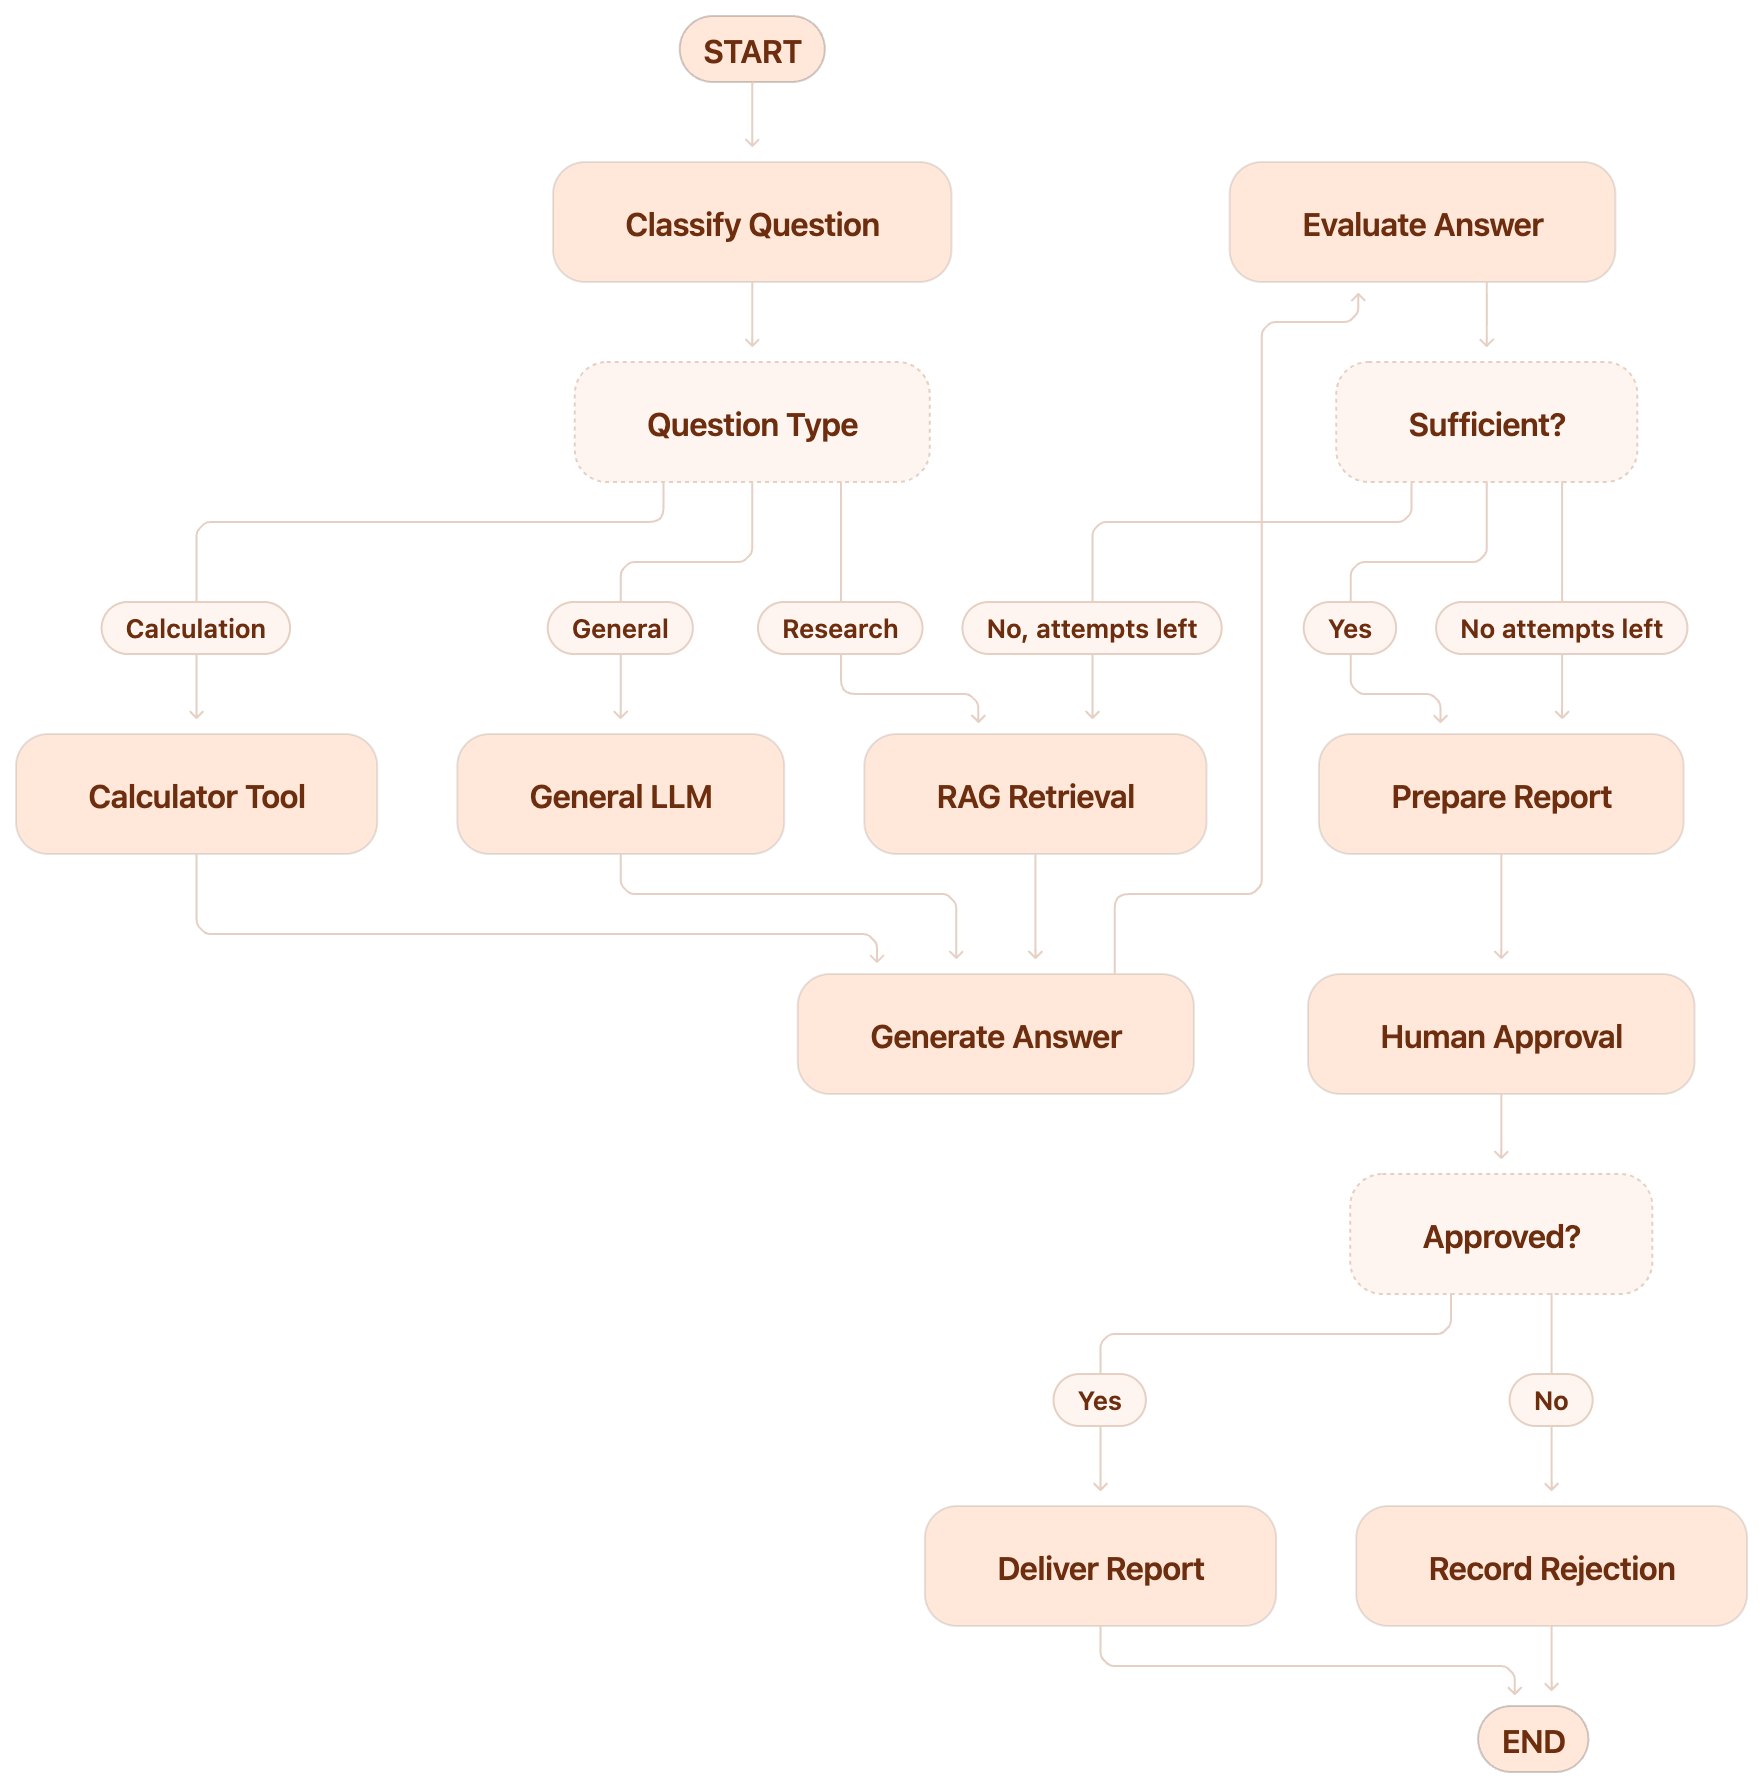